# 02 · Limpieza y corrección de datos

**Limpieza**

Se revisan las 1.010 ofertas de Talento Perú obtenidas en la Parte I. El objetivo es identificar problemas de calidad y entregar un archivo limpio para la siguiente etapa, conservando el archivo original y la trazabilidad de cada oferta.

**Resultado de esta revisión:** se retiraron 4 ofertas con remuneraciones sospechosas de S/ 1, S/ 10 o S/ 200. Una de ellas también tenía el puesto `1`. El archivo limpio conserva 1.006 ofertas y 12 columnas. No se sustituyeron valores sin evidencia. Los valores atípicos altos se conservaron porque ser poco frecuentes no demuestra que sean incorrectos.

El corte corresponde a ofertas publicadas el 17 y 18 de septiembre de 2026. La extracción original ya descartó tarjetas con campos principales vacíos, por lo que este archivo no permite medir los faltantes de las ofertas descartadas.

## Preparación

Se lee el CSV original mediante las rutas y la validación compartidas por el proyecto. Las decisiones se guardan para el informe.

In [1]:
import sys
from pathlib import Path

# Ubica la raíz del repositorio (la carpeta que contiene src/config.py),
# así el notebook funciona desde notebooks/, desde la raíz o en Colab.
RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "config.py").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encontró la raíz del repositorio. Abra el notebook desde la carpeta del proyecto; "
        "en Colab, ejecute antes: !git clone <url del repositorio> y %cd <carpeta del repositorio>"
    )
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import pandas as pd
from src import config, validacion
from src.registro import Registro

registro = Registro("02_limpieza")
df = validacion.cargar_entrada("raw")
df_original = df.copy()

[OK] raw: data/raw/talento_peru_ofertas.csv (1010 filas, 12 columnas)
  ADVERTENCIA: 4 remuneraciones menores a S/ 1000 para revisar: [1.0, 1.0, 10.0, 200.0] (umbral aún no definido en config)
  ADVERTENCIA: 1 ofertas cuyo puesto es solo un número (p. ej. '1')


In [2]:
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_colwidth", 70)
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
display(df.head(3))

/home/gonzalo/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-30p7rh1j because there was an issue with the default path (/home/gonzalo/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Filas: 1010 | Columnas: 12


,id_oferta_hash,puesto,entidad,ubicacion,numero_convocatoria,vacantes,remuneracion_pen,fecha_inicio_publicacion,fecha_fin_publicacion,pagina_origen,fuente_url,fecha_extraccion_utc
0,1af30dbb2f0f39e7d0c908cf,ESPECIALISTA LEGAL,PODER JUDICIAL,JUNIN - EL TAMBO,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-093,1,5670.0,2026-09-18,2026-10-01,1,https://app.servir.gob.pe/DifusionOfertasExterno/faces/consultas/o...,2026-09-18T05:58:55.931516+00:00
1,febb4d4b3da59b587a74d154,ASISTENTE LEGAL,PODER JUDICIAL,JUNIN - EL TAMBO,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-092,1,4000.0,2026-09-18,2026-10-01,1,https://app.servir.gob.pe/DifusionOfertasExterno/faces/consultas/o...,2026-09-18T05:58:55.931516+00:00
2,dcde0256d3fc65eed01f4f18,ASISTENTE ADMINISTRATIVO I MODULO,PODER JUDICIAL,JUNIN - EL TAMBO,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-092,1,3470.0,2026-09-18,2026-10-01,1,https://app.servir.gob.pe/DifusionOfertasExterno/faces/consultas/o...,2026-09-18T05:58:55.931516+00:00


## 1. Diagnóstico inicial

Revisamos la estructura, los tipos y los rangos de las variables numéricas y fechas. Cada fila representa una oferta extraída del listado, no necesariamente una convocatoria completa.

In [3]:
df.info()
display(df[["vacantes", "remuneracion_pen"]].describe().round(2))
print("Fechas de inicio:", df["fecha_inicio_publicacion"].min(), "a", df["fecha_inicio_publicacion"].max())
print("Fechas de fin:", df["fecha_fin_publicacion"].min(), "a", df["fecha_fin_publicacion"].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_oferta_hash            1010 non-null   object 
 1   puesto                    1010 non-null   object 
 2   entidad                   1010 non-null   object 
 3   ubicacion                 1010 non-null   object 
 4   numero_convocatoria       1010 non-null   object 
 5   vacantes                  1010 non-null   int64  
 6   remuneracion_pen          1010 non-null   float64
 7   fecha_inicio_publicacion  1010 non-null   object 
 8   fecha_fin_publicacion     1010 non-null   object 
 9   pagina_origen             1010 non-null   int64  
 10  fuente_url                1010 non-null   object 
 11  fecha_extraccion_utc      1010 non-null   object 
dtypes: float64(1), int64(2), object(9)
memory usage: 94.8+ KB


,vacantes,remuneracion_pen
count,1010.00,1010.00
mean,1.74,5130.15
std,3.21,2503.32
min,1.00,1.00
25%,1.00,3100.00
50%,1.00,5353.30
75%,1.00,6500.00
max,72.00,21000.00


Fechas de inicio: 2026-09-17 a 2026-09-18
Fechas de fin: 2026-09-30 a 2026-10-01


## 2. Valores faltantes

Además de los nulos, buscamos textos vacíos o marcadores comunes en las cuatro columnas descriptivas. No se imputan valores si no hay faltantes identificados. El archivo inicial excluyó ofertas incompletas durante la extracción. Por eso esta revisión se limita a las filas conservadas.

In [4]:
columnas_texto = ["puesto", "entidad", "ubicacion", "numero_convocatoria"]
marcadores = {"", "-", "--", "S/N", "N/A", "NO ESPECIFICA", "NO ESPECIFICADO"}
nulos = df.isna().sum()
marcadores_por_columna = {}
for columna in columnas_texto:
    valores = df[columna].fillna("").astype(str).str.strip().str.upper()
    marcadores_por_columna[columna] = int(valores.isin(marcadores).sum())
display(pd.DataFrame({"nulos": nulos, "porcentaje_nulos": (nulos / len(df) * 100).round(2)}))
print("Marcadores de faltantes en columnas descriptivas:", marcadores_por_columna)
registro.agregar("Valores faltantes", "Se revisaron nulos y marcadores y no se imputaron valores", int(nulos.sum()) + sum(marcadores_por_columna.values()), "No se detectaron faltantes entre las filas conservadas. La extracción descartó previamente ofertas incompletas.")

,nulos,porcentaje_nulos
id_oferta_hash,0,0.0
puesto,0,0.0
entidad,0,0.0
ubicacion,0,0.0
numero_convocatoria,0,0.0
vacantes,0,0.0
remuneracion_pen,0,0.0
fecha_inicio_publicacion,0,0.0
fecha_fin_publicacion,0,0.0
pagina_origen,0,0.0


Marcadores de faltantes en columnas descriptivas: {'puesto': 0, 'entidad': 0, 'ubicacion': 0, 'numero_convocatoria': 0}


## 3. Duplicados e inconsistencias

Primero revisamos filas completas, identificadores y la combinación de los ocho campos de la oferta. También exploramos una clave más corta (entidad, convocatoria y puesto). Esa clave puede repetirse para ubicaciones o importes diferentes, por lo que no basta para eliminar registros.

In [5]:
clave_corta = ["entidad", "numero_convocatoria", "puesto"]
repetidos_clave = df.duplicated(clave_corta, keep=False)
print("Filas completas duplicadas:", df.duplicated().sum())
print("Identificadores duplicados:", df["id_oferta_hash"].duplicated().sum())
print("Ofertas duplicadas en los 8 campos principales:", df.duplicated(config.CAMPOS_PRINCIPALES).sum())
print("Filas que comparten la clave corta:", repetidos_clave.sum())
display(df.loc[repetidos_clave, clave_corta + ["ubicacion", "remuneracion_pen"]].sort_values(clave_corta).head(8))
registro.agregar("Duplicados", "Se conservaron las ofertas con clave corta repetida", int(repetidos_clave.sum()), "La clave corta no identifica de forma única la oferta: puede haber distintas ubicaciones o remuneraciones. No se encontraron duplicados en los ocho campos principales.")

Filas completas duplicadas: 0
Identificadores duplicados: 0
Ofertas duplicadas en los 8 campos principales: 0
Filas que comparten la clave corta: 85


,entidad,numero_convocatoria,puesto,ubicacion,remuneracion_pen
464,AIS UTES PACASMAYO,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-9,ENFERMERA/O,LA LIBERTAD - PACASMAYO,3750.00
466,AIS UTES PACASMAYO,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-9,ENFERMERA/O,LA LIBERTAD - SAN JOSE,3335.81
449,CORTE SUPERIOR DE JUSTICIA DE LAMBAYEQUE,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-029,ESPECIALISTA JUDICIAL,LAMBAYEQUE - CHICLAYO,4750.00
632,CORTE SUPERIOR DE JUSTICIA DE LAMBAYEQUE,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-029,ESPECIALISTA JUDICIAL,CAJAMARCA - JAEN,4750.00
442,CORTE SUPERIOR DE JUSTICIA DE LIMA ESTE,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-021,ESPECIALISTA LEGAL DE DESCARGA,LIMA - SANTA ANITA,5670.00
443,CORTE SUPERIOR DE JUSTICIA DE LIMA ESTE,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-021,ESPECIALISTA LEGAL DE DESCARGA,LIMA - SAN JUAN DE LURIGANCHO,5670.00
524,CORTE SUPERIOR DE JUSTICIA DE LIMA ESTE,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-021,ESPECIALISTA LEGAL DE DESCARGA,LIMA - ATE,5670.00
529,CORTE SUPERIOR DE JUSTICIA DE LIMA ESTE,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-021,ESPECIALISTA LEGAL DE DESCARGA,LIMA - LA MOLINA,5670.00


Revisamos espacios, campos numéricos, fechas y puestos compuestos solo por números. No cambiamos las categorías por similitud sin comprobar que representen la misma entidad o puesto.

In [6]:
espacios = {}
for columna in columnas_texto:
    original = df[columna].astype(str)
    limpio = original.str.strip().str.replace(r"\s+", " ", regex=True)
    espacios[columna] = int((original != limpio).sum())

fechas_invalidas = {}
for columna in config.COLUMNAS_FECHA:
    fechas = pd.to_datetime(df[columna], format="%Y-%m-%d", errors="coerce")
    fechas_invalidas[columna] = int(fechas.isna().sum())
fechas_invertidas = pd.to_datetime(df["fecha_fin_publicacion"]) < pd.to_datetime(df["fecha_inicio_publicacion"])
puesto_numerico = df["puesto"].astype(str).str.strip().str.fullmatch(r"\d+")
print("Textos con espacios por normalizar:", espacios)
print("Fechas inválidas:", fechas_invalidas, "| Fechas de fin anteriores al inicio:", fechas_invertidas.sum())
print("Vacantes menores a 1:", (df["vacantes"] < 1).sum())
print("Puestos solo numéricos:", puesto_numerico.sum())
display(df.loc[puesto_numerico, ["id_oferta_hash", "puesto", "entidad", "remuneracion_pen"]])
registro.agregar("Consistencia", "Se revisaron textos, fechas, vacantes y puesto numérico", int(puesto_numerico.sum()), "No se puede recuperar el nombre del puesto a partir del listado. El registro coincide con una remuneración sospechosa y se retira en el siguiente paso.")

Textos con espacios por normalizar: {'puesto': 0, 'entidad': 0, 'ubicacion': 0, 'numero_convocatoria': 0}
Fechas inválidas: {'fecha_inicio_publicacion': 0, 'fecha_fin_publicacion': 0} | Fechas de fin anteriores al inicio: 0
Vacantes menores a 1: 0
Puestos solo numéricos: 1


,id_oferta_hash,puesto,entidad,remuneracion_pen
68,6a5d550df8f03240b07c6657,1,SERVICIO NACIONAL DE SANIDAD AGRARIA,1.0


## 4. Valores atípicos y corrección

Usamos el rango intercuartílico para detectar valores alejados de la distribución. Es una señal para revisar, no una prueba de error. En vacantes, Q1 y Q3 son 1. Por ello el límite superior también es 1 y clasifica como atípica cualquier oferta con más de una vacante. No sería razonable eliminarlas por ese motivo.

,variable,Q1,Q3,límite inferior,límite superior,filas señaladas
0,remuneracion_pen,3100.0,6500.0,-2000.0,11600.0,19
1,vacantes,1.0,1.0,1.0,1.0,188


/tmp/ipykernel_12/50806443.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=False, flierprops={"markersize": 3})
/tmp/ipykernel_12/50806443.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(df[col], vert=False, flierprops={"markersize": 3})


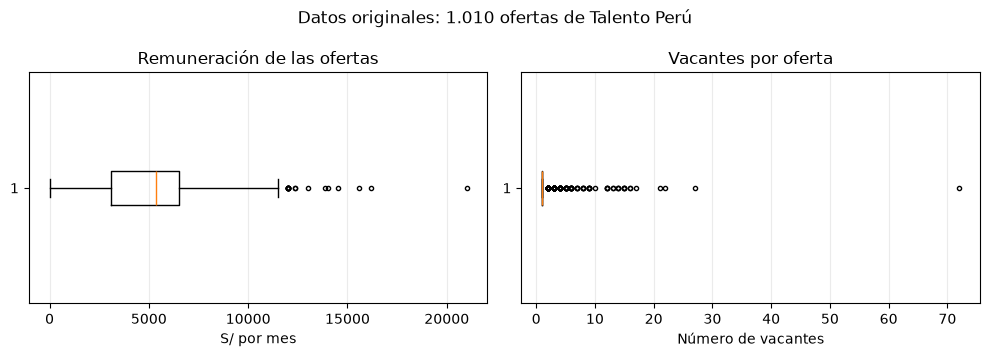

In [7]:
resumen_iqr = []
for columna in ["remuneracion_pen", "vacantes"]:
    q1, q3 = df[columna].quantile([0.25, 0.75])
    iqr = q3 - q1
    inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    cantidad = ((df[columna] < inferior) | (df[columna] > superior)).sum()
    resumen_iqr.append({"variable": columna, "Q1": q1, "Q3": q3, "límite inferior": inferior, "límite superior": superior, "filas señaladas": int(cantidad)})
display(pd.DataFrame(resumen_iqr).round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, col, titulo, unidad in zip(axes, ["remuneracion_pen", "vacantes"], ["Remuneración de las ofertas", "Vacantes por oferta"], ["S/ por mes", "Número de vacantes"]):
    ax.boxplot(df[col], vert=False, flierprops={"markersize": 3})
    ax.set(title=titulo, xlabel=unidad)
    ax.grid(axis="x", alpha=0.25)
fig.suptitle("Datos originales: 1.010 ofertas de Talento Perú")
fig.tight_layout()
plt.show()

En remuneraciones, el límite superior del rango intercuartílico identifica 19 ofertas. Se conservan porque importes altos pueden corresponder a puestos con distintas responsabilidades. En vacantes, el método señala 188 ofertas por la concentración en una sola vacante. No se recortan ni reemplazan esos valores.

### Revisión bivariada

Usamos un gráfico de dispersión para revisar la cantidad de vacantes y la remuneración al mismo tiempo. Esto permite identificar combinaciones alejadas de las demás, aunque el gráfico por sí solo no demuestra que sean errores.

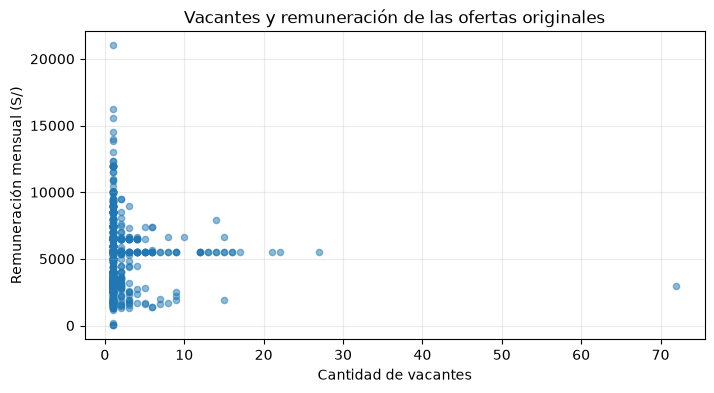

,puesto,vacantes,remuneracion_pen
105,ESPECIALISTA JUDICIAL DE JUZGADO,72,2972.0
730,PERFIL 665-2026 AUDITOR/A ANALISTA I EN SISTEMAS ADMINISTRATIVOS,27,5500.0
938,PERFIL 592-2026 AUDITOR/A ANALISTA I EN SISTEMAS ADMINISTRATIVOS,22,5500.0


In [8]:
plt.figure(figsize=(8, 4))
plt.scatter(df["vacantes"], df["remuneracion_pen"], alpha=0.5, s=20)
plt.title("Vacantes y remuneración de las ofertas originales")
plt.xlabel("Cantidad de vacantes")
plt.ylabel("Remuneración mensual (S/)")
plt.grid(alpha=0.25)
plt.show()

display(df.nlargest(3, "vacantes")[["puesto", "vacantes", "remuneracion_pen"]])

La mayoría de ofertas tiene pocas vacantes. Se observa una oferta con 72 vacantes y remuneración de S/ 2.972, separada del resto por su cantidad de vacantes. Se conserva: una convocatoria puede ofrecer varias plazas y no tenemos evidencia para considerarla incorrecta.

### Revisión con la remuneración mínima de septiembre de 2026

La remuneración mínima vital (RMV) era de **S/ 1.130** cuando se publicaron las ofertas del 17 y 18 de septiembre de 2026. El [Decreto Supremo N.° 006-2024-TR](https://www.gob.pe/institucion/mtpe/normas-legales/6335262-006-2024-tr) fijó ese monto desde enero de 2025. El aumento a S/ 1.230 empezó el 1 de octubre de 2026, después del corte, según el [Decreto Supremo N.° 015-2026-TR](https://busquedas.elperuano.pe/dispositivo/EX/2559163-1/pdf/).

Las cinco ofertas bajo S/ 1.130 indican D. Leg. 1057 en el número de convocatoria. La referencia de SERVIR señala que la retribución CAS no debe ser menor que la RMV ([informe técnico citado por el Poder Judicial](https://www.pj.gob.pe/wps/wcm/connect/c0eaf78041115926b5fdbf1666a80600/RESOLUCION%2BADMINISTRATIVA%2B515-2024-GG-PJ.pdf?CACHEID=c0eaf78041115926b5fdbf1666a80600)). El CSV no contiene las bases ni el detalle de la jornada, por lo que esta comparación identifica casos para revisar y no prueba por sí sola un error o incumplimiento.

Los importes de S/ 1, S/ 10 y S/ 200 son extremadamente bajos para una remuneración mensual. Se excluyen las cuatro ofertas correspondientes como decisión conservadora, sin reemplazar sus valores. La oferta de **S/ 1.126,70**, próxima a la RMV, se conserva y queda identificada para contrastar con la ficha original. No aplicamos un filtro automático por debajo de la RMV a todo el dataset ni afirmamos que el valor publicado sea ilegal.

In [9]:
sospechosas = df["remuneracion_pen"].isin([1, 10, 200])
rmv_septiembre_2026 = 1130
bajo_rmv = df["remuneracion_pen"] < rmv_septiembre_2026
campos_revision = ["id_oferta_hash", "puesto", "entidad", "ubicacion", "numero_convocatoria", "vacantes", "remuneracion_pen"]
display(df.loc[bajo_rmv, campos_revision])
print("Ofertas por debajo de la RMV de septiembre de 2026:", int(bajo_rmv.sum()))
print("De ellas, las que indican D. Leg. 1057:", int(df.loc[bajo_rmv, "numero_convocatoria"].str.contains("1057", na=False).sum()))
print("Ofertas con importe sospechoso:", int(sospechosas.sum()))
print("De ellas, puestos solo numéricos:", int((sospechosas & puesto_numerico).sum()))
registro.agregar("Valores atípicos", "Se conservaron los valores altos señalados por el rango intercuartílico", int(sum(item["filas señaladas"] for item in resumen_iqr)), "Ser atípico no prueba un error. Las ofertas pueden tener distintas remuneraciones o varias vacantes. La suma de señales puede contar una misma fila más de una vez.")
registro.agregar("Referencia RMV", "Se revisaron importes inferiores a S/ 1.130 y se conservó el de S/ 1.126,70", int(bajo_rmv.sum()), "RMV vigente en septiembre de 2026. Las cinco convocatorias indican D. Leg. 1057. Sin las bases y jornada, la comparación no confirma un error ni una infracción. Se conservó el importe cercano y se excluyeron los cuatro extremos en el siguiente paso.")
registro.agregar("Remuneraciones sospechosas", "Se excluyeron las ofertas con importes observados de S/ 1, S/ 10 o S/ 200", int(sospechosas.sum()), "Importes muy bajos para la remuneración mensual descrita. No hay evidencia para corregirlos. Una oferta también tiene el puesto 1. Decisión sujeta a revisión si se recupera la fuente.")
registro.agregar("Puesto inválido", "El puesto numérico está entre las ofertas excluidas", int(puesto_numerico.sum()), "El único puesto numérico ya está comprendido en la exclusión por remuneración sospechosa. No se cuenta dos veces.")
df = df.loc[~(sospechosas | puesto_numerico)].copy()

,id_oferta_hash,puesto,entidad,ubicacion,numero_convocatoria,vacantes,remuneracion_pen
30,111ad49f37c514c5f11e7888,SECRETARIO/A TÉCNICO/A DE LOS ÓRGANOS INSTRUCTORES DEL PROCEDIMIEN...,INSTITUTO NACIONAL DE INNOVACION AGRARIA,LIMA - LA MOLINA,D.LEG 1057 - DETERMINADO (SUPLENCIA)-088,1,10.0
68,6a5d550df8f03240b07c6657,1,SERVICIO NACIONAL DE SANIDAD AGRARIA,LAMBAYEQUE - CAÑARIS,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-1,1,1.0
378,5a9e3a528f784f16fea79067,BIOLOGO(A),GERENCIA REGIONAL DE SALUD LA LIBERTAD,LA LIBERTAD - BOLIVAR,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-003,1,1.0
402,66a0b7aead414097a8ebb3c5,PROGRAMA PRESUPUESTAL PPR 017 – ENFERMEDADES METAXENICAS Y ZOONOSIS,UNIDAD EJECUTORA 404 HOSPITAL SAN JUAN DE DIOS - PISCO,ICA - PISCO,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-02,1,1126.7
656,2a8062e1f2afe51a30243a83,ESPECIALISTA EN EVALUACION DE MANTENIMIENTOS DE INFRAESTRUCTURA PU...,MUNICIPALIDAD DISTRITAL DE YURA,AREQUIPA - YURA,D.LEG 1057 - DETERMINADO (NECESIDAD TRANSITORIA)-14,1,200.0


Ofertas por debajo de la RMV de septiembre de 2026: 5
De ellas, las que indican D. Leg. 1057: 5
Ofertas con importe sospechoso: 4
De ellas, puestos solo numéricos: 1


## 5. Registro de decisiones

El registro resume las revisiones y los cambios. Las filas afectadas por cada revisión no se suman entre sí, porque una misma oferta puede aparecer en más de una comprobación.

In [10]:
display(registro.tabla().drop(columns=["fecha"]))

,etapa,n,paso,accion,filas_afectadas,justificacion
0,02_limpieza,1,Valores faltantes,Se revisaron nulos y marcadores y no se imputaron valores,0,No se detectaron faltantes entre las filas conservadas. La extracc...
1,02_limpieza,2,Duplicados,Se conservaron las ofertas con clave corta repetida,85,La clave corta no identifica de forma única la oferta: puede haber...
2,02_limpieza,3,Consistencia,"Se revisaron textos, fechas, vacantes y puesto numérico",1,No se puede recuperar el nombre del puesto a partir del listado. E...
3,02_limpieza,4,Valores atípicos,Se conservaron los valores altos señalados por el rango intercuart...,207,Ser atípico no prueba un error. Las ofertas pueden tener distintas...
4,02_limpieza,5,Referencia RMV,Se revisaron importes inferiores a S/ 1.130 y se conservó el de S/...,5,RMV vigente en septiembre de 2026. Las cinco convocatorias indican...
5,02_limpieza,6,Remuneraciones sospechosas,"Se excluyeron las ofertas con importes observados de S/ 1, S/ 10 o...",4,Importes muy bajos para la remuneración mensual descrita. No hay e...
6,02_limpieza,7,Puesto inválido,El puesto numérico está entre las ofertas excluidas,1,El único puesto numérico ya está comprendido en la exclusión por r...


## 6. Guardado y validación

El archivo limpio mantiene las columnas y los identificadores originales. El identificador permite rastrear cada fila en el CSV original. No se recalcula ni se interpreta como una nueva oferta. Se comprueba la salida con el contrato del proyecto.

In [11]:
print(f"Filas: {len(df_original)} → {len(df)} ({len(df_original) - len(df)} excluidas)")
config.asegurar_carpetas()
df.to_csv(config.ARCHIVO_LIMPIO, index=False, encoding=config.ENCODING)
registro.guardar()
_ = validacion.validar("limpio").exigir()

Filas: 1010 → 1006 (4 excluidas)


[OK] limpio: data/interim/talento_peru_limpio.csv (1006 filas, 12 columnas)

El dataset limpio queda disponible para la transformación. Se conserva una oferta de S/ 1.126,70 para revisión porque no se pudo contrastar con su ficha. Como limitaciones, el corte proviene de una sola fuente y de dos días de publicación. Tampoco se pudieron contrastar los cuatro importes excluidos. Estas decisiones deben tenerse en cuenta durante la transformación de los datos.